# Transformers against state space models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/09-new-backbones/notebook.ipynb)

Companion to the article *Does Music AI Need a New Engine? Transformers Against State Space Models, Measured*. We count attention's pairs, work a one-number state by hand, build a selective state space block (the core of Mamba) in about 30 lines, time it against attention as the sequence grows, and train both on Bach chorales.

Runs on a CPU. No model downloads.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q music21

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import math, time, torch, torch.nn as nn, torch.nn.functional as F

def synth(notes, sr=22050, harmonics=(1, 0.5, 0.33, 0.25, 0.2), decay=0.8):
    """Notes as (start seconds, duration seconds, MIDI pitch) -> sound."""
    y = np.zeros(int((max(s + d for s, d, _ in notes) + 0.3) * sr))
    for s, d, p in notes:
        f = 440 * 2 ** ((p - 69) / 12); n = int(d * sr); t = np.arange(n) / sr
        tone = sum(a * np.sin(2 * np.pi * f * (k + 1) * t) for k, a in enumerate(harmonics) if f * (k + 1) < sr / 2)
        i = int(s * sr); y[i:i + n] += tone * np.exp(-decay * t) * np.minimum(1, t / 0.01) * np.minimum(1, (d - t) / 0.02)
    return (0.9 * y / np.abs(y).max()).astype(np.float32)

## 1. Attention's bill

In [3]:
for label, sec in (("30 s", 30), ("3 minutes", 180), ("10 minutes", 600), ("1 hour", 3600)):
    n = sec * 50; print(f"{label:11s} {n:>8,} frames  {n * n:>15,} pairs  {n * n * 4 / 1e6:>10,.0f} MB per table of scores")

30 s           1,500 frames        2,250,000 pairs           9 MB per table of scores
3 minutes      9,000 frames       81,000,000 pairs         324 MB per table of scores
10 minutes    30,000 frames      900,000,000 pairs       3,600 MB per table of scores
1 hour       180,000 frames   32,400,000,000 pairs     129,600 MB per table of scores


## 2. A state of one number

`h = a * h + b * x`. With a = 0.5 an input fades by half per step. The half-life in steps is ln 0.5 / ln a.

In [4]:
h = 0.0
for t, x in enumerate([1, 0, 0, 0, 0]):
    h = 0.5 * h + x; print(f"t={t}  input {x}  state {h}")
print()
for a in (0.5, 0.9, 0.99, 0.999, 0.9999):
    n = math.log(0.5) / math.log(a); print(f"a = {a:<7} half-life {n:>7,.0f} steps = {n / 50:>7.2f} s of music at 50 frames per second")

t=0  input 1  state 1.0
t=1  input 0  state 0.5
t=2  input 0  state 0.25
t=3  input 0  state 0.125
t=4  input 0  state 0.0625

a = 0.5     half-life       1 steps =    0.02 s of music at 50 frames per second
a = 0.9     half-life       7 steps =    0.13 s of music at 50 frames per second
a = 0.99    half-life      69 steps =    1.38 s of music at 50 frames per second
a = 0.999   half-life     693 steps =   13.86 s of music at 50 frames per second
a = 0.9999  half-life   6,931 steps =  138.62 s of music at 50 frames per second


## 3. Selection

Let the input choose a and b. Rule: a marked input wipes the state and stores itself; anything else is ignored.

In [5]:
h = 0.0
for t, (x, marked) in enumerate([(3, False), (7, True), (4, False), (9, False), (2, False), (5, False)]):
    a, b = (0, 1) if marked else (1, 0); h = a * h + b * x
    print(f"t={t}  input {x}{'*' if marked else ' '}  a={a} b={b}  state {h}")

t=0  input 3   a=1 b=0  state 0.0
t=1  input 7*  a=0 b=1  state 7.0
t=2  input 4   a=1 b=0  state 7.0
t=3  input 9   a=1 b=0  state 7.0
t=4  input 2   a=1 b=0  state 7.0
t=5  input 5   a=1 b=0  state 7.0


## 4. The real block

The same recurrence for many states at once, with the keep and write amounts computed from the input by small learned layers. The scan handles 8 time steps per pass to keep Python overhead down; `chunk=1` is the recurrence exactly as written, and the last lines check that both give the same numbers.

In [6]:
class SelectiveSSM(nn.Module):
    def __init__(self, d, expand=2, state=16, conv=4, chunk=8):
        super().__init__()
        self.di, self.N, self.rank, self.chunk = d * expand, state, math.ceil(d / 16), chunk
        self.inp = nn.Linear(d, 2 * self.di, bias=False)
        self.conv = nn.Conv1d(self.di, self.di, conv, padding=conv - 1, groups=self.di)
        self.to_params = nn.Linear(self.di, self.rank + 2 * state, bias=False)
        self.dt = nn.Linear(self.rank, self.di)
        self.A_log = nn.Parameter(torch.log(torch.arange(1, state + 1).float()).repeat(self.di, 1))
        self.D = nn.Parameter(torch.ones(self.di)); self.out = nn.Linear(self.di, d, bias=False)
    def forward(self, u):
        T = u.shape[1]; x, z = self.inp(u).chunk(2, dim=-1)
        x = F.silu(self.conv(x.transpose(1, 2))[..., :T].transpose(1, 2))
        dt, B, C = self.to_params(x).split([self.rank, self.N, self.N], dim=-1)
        dt = F.softplus(self.dt(dt)); A = -torch.exp(self.A_log)
        h = torch.zeros(u.shape[0], self.di, self.N); ys = []
        for i in range(0, T, self.chunk):
            j = min(T, i + self.chunk); d_ = dt[:, i:j]
            log_keep = (d_.unsqueeze(-1) * A).clamp(min=-10)                 # log of how much old state survives
            write = (d_ * x[:, i:j]).unsqueeze(-1) * B[:, i:j].unsqueeze(2)  # what each input adds
            if self.chunk == 1: hs = (torch.exp(log_keep[:, 0]) * h + write[:, 0]).unsqueeze(1)     # h = keep * h + write
            else:
                P = log_keep.cumsum(1); hs = torch.exp(P) * (h.unsqueeze(1) + (torch.exp(-P) * write).cumsum(1))
            ys.append((hs * C[:, i:j].unsqueeze(2)).sum(-1)); h = hs[:, -1]
        return self.out((torch.cat(ys, 1) + x * self.D) * F.silu(z))

class Block(nn.Module):
    def __init__(self, d): super().__init__(); self.norm, self.ssm = nn.LayerNorm(d), SelectiveSSM(d)
    def forward(self, x): return x + self.ssm(self.norm(x))

torch.manual_seed(0); b = Block(128); x = torch.randn(2, 200, 128)
slow = Block(128); slow.load_state_dict(b.state_dict()); slow.ssm.chunk = 1
x2 = x.clone(); x2[:, 150:] += 1.0
with torch.no_grad():
    print(f"{sum(p.numel() for p in b.parameters()):,} parameters; state per layer: {b.ssm.di} channels x {b.ssm.N} = {b.ssm.di * b.ssm.N:,} numbers")
    print("8 steps per pass equals 1 step per pass:", torch.allclose(b(x), slow(x), atol=1e-4))
    print("changing the future leaves the past unchanged:", torch.allclose(b(x)[:, :150], b(x2)[:, :150], atol=1e-5))

116,736 parameters; state per layer: 256 channels x 16 = 4,096 numbers
8 steps per pass equals 1 step per pass: True
changing the future leaves the past unchanged: True


## 5. How each one grows

One layer of each, 256 wide, forward pass only. Watch the ratio from one row to the next: attention's time should approach 4x per doubling, the state space layer's 2x.

In [7]:
D = 256; torch.manual_seed(0)
att = nn.MultiheadAttention(D, 4, batch_first=True); ssm = SelectiveSSM(D); rows = []
with torch.no_grad():
    for n in (512, 1024, 2048, 4096, 8192, 16384):
        x = torch.randn(1, n, D); mask = torch.triu(torch.ones(n, n, dtype=torch.bool), 1)
        t0 = time.time(); att(x, x, x, attn_mask=mask, need_weights=False); ta = time.time() - t0
        t0 = time.time(); ssm(x); ts = time.time() - t0
        rows.append((n, ta, ts)); print(f"{n:>6,} frames ({n / 50:>5.0f} s of music)   attention {ta:6.3f} s, table {n * n * 4 * 4 / 1e6:>6,.0f} MB for 4 heads   state space {ts:6.3f} s")

   512 frames (   10 s of music)   attention  0.002 s, table      4 MB for 4 heads   state space  0.060 s


 1,024 frames (   20 s of music)   attention  0.004 s, table     17 MB for 4 heads   state space  0.102 s


 2,048 frames (   41 s of music)   attention  0.008 s, table     67 MB for 4 heads   state space  0.186 s


 4,096 frames (   82 s of music)   attention  0.025 s, table    268 MB for 4 heads   state space  0.295 s


 8,192 frames (  164 s of music)   attention  0.086 s, table  1,074 MB for 4 heads   state space  0.533 s


16,384 frames (  328 s of music)   attention  0.261 s, table  4,295 MB for 4 heads   state space  1.170 s


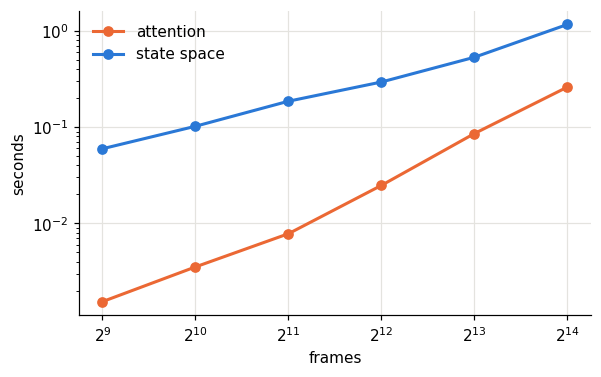

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot([r[0] for r in rows], [r[1] for r in rows], color=ORANGE, marker="o", label="attention")
ax.plot([r[0] for r in rows], [r[2] for r in rows], color=BLUE, marker="o", label="state space")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("frames"); ax.set_ylabel("seconds"); ax.legend(frameon=False); plt.show()

## 6. Both on the same music

Next-token prediction on the 371 Bach chorales that ship with `music21` (reading them takes about 20 seconds). `STEPS = 100` takes about half a minute for the transformer and about five minutes for the state space model here; the article uses 800.

In [9]:
import music21 as m21
chorales = []
for c in m21.corpus.chorales.Iterator():
    key = c.analyze("key"); notes = set()
    for n in c.flatten().notes:
        for p in n.pitches:
            if n.duration.quarterLength > 0: notes.add((round(float(n.offset) * 4), max(1, round(float(n.duration.quarterLength) * 4)), p.midi))
    chorales.append({"tonic": key.tonic.pitchClass, "mode": key.mode, "notes": sorted(notes)})

LO, HI, CTX, DM = 30, 90, 256, 128
VOCAB = ["BAR"] + [f"POS_{i}" for i in range(16)] + [f"PITCH_{p}" for p in range(LO, HI)] + [f"DUR_{d}" for d in range(1, 17)]
ID = {t: i for i, t in enumerate(VOCAB)}; V = len(VOCAB)
def encode(c):
    shift = (-c["tonic"] if c["mode"] == "major" else 9 - c["tonic"]) % 12
    if shift > 6: shift -= 12
    out, last_bar, last_pos = [], -1, None
    for s, d, p in sorted(c["notes"], key=lambda n: (n[0], -n[2])):
        bar, pos = divmod(s, 16)
        while last_bar < bar: out.append(ID["BAR"]); last_bar += 1; last_pos = None
        if pos != last_pos: out.append(ID[f"POS_{pos}"]); last_pos = pos
        out += [ID[f"PITCH_{min(HI - 1, max(LO, p + shift))}"], ID[f"DUR_{min(16, d)}"]]
    return out
def decode(ids):
    notes, bar, pos, pitch, prev = [], -1, None, None, None
    for i in ids:
        k, v = VOCAB[i].split("_")[0], VOCAB[i].split("_")[-1]
        legal = {"BAR": prev in (None, "BAR", "DUR"), "POS": prev in ("BAR", "DUR"), "PITCH": prev in ("POS", "DUR"), "DUR": prev == "PITCH"}[k]
        if k == "POS" and legal and prev == "DUR" and int(v) <= pos: legal = False
        if not legal: continue
        if k == "BAR": bar += 1; pos = None
        elif k == "POS": pos = int(v)
        elif k == "PITCH": pitch = int(v)
        else: notes.append((bar * 16 + pos, int(v), pitch))
        prev = k
    return notes
order = np.random.default_rng(0).permutation(len(chorales)); n_val = len(chorales) // 10
val = [encode(chorales[i]) for i in order[:n_val]]; train = [encode(chorales[i]) for i in order[n_val:]]
print(len(train), "training chorales,", len(val), "held out; longest held-out chorale:", max(map(len, val)), "tokens")

334 training chorales, 37 held out; longest held-out chorale: 1114 tokens


In [10]:
class Transformer(nn.Module):
    def __init__(s):
        super().__init__(); s.tok, s.pos = nn.Embedding(V, DM), nn.Embedding(CTX, DM)
        layer = nn.TransformerEncoderLayer(DM, 4, 4 * DM, dropout=0.1, batch_first=True, norm_first=True)
        s.body, s.norm, s.head = nn.TransformerEncoder(layer, 4), nn.LayerNorm(DM), nn.Linear(DM, V)
    def forward(s, x):
        T = x.shape[1]; return s.head(s.norm(s.body(s.tok(x) + s.pos(torch.arange(T)), mask=torch.triu(torch.full((T, T), float("-inf")), 1))))
class StateSpace(nn.Module):
    def __init__(s):
        super().__init__(); s.tok = nn.Embedding(V, DM)
        s.body, s.norm, s.head = nn.Sequential(*[Block(DM) for _ in range(4)]), nn.LayerNorm(DM), nn.Linear(DM, V)
    def forward(s, x): return s.head(s.norm(s.body(s.tok(x))))

def held_out(model, window):
    model.eval(); tot = cnt = 0
    with torch.no_grad():
        for s in val:
            w = window or len(s)
            for i in range(0, len(s) - 1, w):
                x = torch.tensor(s[i:i + w + 1])[None]
                if x.shape[1] > 1: tot += F.cross_entropy(model(x[:, :-1])[0], x[0, 1:], reduction="sum").item(); cnt += x.shape[1] - 1
    model.train(); return tot / cnt

STEPS, models = 100, {}
for name, cls in (("transformer", Transformer), ("state space", StateSpace)):
    torch.manual_seed(0); rng = np.random.default_rng(1); model = cls()
    opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=0.01); sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=STEPS)
    t0 = time.time()
    for step in range(STEPS):
        xs = []
        for _ in range(32):
            s = train[rng.integers(len(train))]; i = rng.integers(0, max(1, len(s) - CTX - 1)); xs.append(s[i:i + CTX + 1])
        n = min(map(len, xs)); x = torch.tensor([q[:n] for q in xs])
        loss = F.cross_entropy(model(x[:, :-1]).reshape(-1, V), x[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    models[name] = model
    print(f"{name:12s} {sum(p.numel() for p in model.parameters()):>8,} parameters   {(time.time() - t0) / STEPS:.2f} s per step   held-out loss {held_out(model, CTX):.3f}")
print(f"\nstate space model reading whole chorales at once, up to {max(map(len, val))} tokens: held-out loss {held_out(models['state space'], None):.3f}")
print("the transformer cannot: it has a position table of", CTX, "entries")

transformer   850,013 parameters   0.29 s per step   held-out loss 2.219


state space   491,101 parameters   3.28 s per step   held-out loss 1.306



state space model reading whole chorales at once, up to 1114 tokens: held-out loss 1.298
the transformer cannot: it has a position table of 256 entries


Listen to eight bars from each (after 100 steps, neither is Bach yet).

In [11]:
SIX = 60 / 80 / 4
for name, model in models.items():
    model.eval(); x = torch.tensor([[ID["BAR"]]])
    with torch.no_grad():
        for _ in range(240): x = torch.cat([x, torch.multinomial(torch.softmax(model(x[:, -CTX:])[:, -1], -1), 1)], 1)
    notes = [n for n in decode(x[0].tolist()) if n[0] < 16 * 8]
    print(name); display(Audio(synth([(s * SIX, d * SIX, p) for s, d, p in notes]), rate=22050))

transformer


[audio player: run the cell to listen]


state space


[audio player: run the cell to listen]
